# Apéndice: ¿simplificar el Portafolio J?
**Autor:** Andrés Alejandro Rodríguez Lozano · Octubre 2026

> 🧪 **Laboratorio, no recomendación.** Material educativo. Los tickers analizados están por fuera de la tesis del core; nada de esto es un candidato a mezcla.

**Hipótesis a poner a prueba:** *cortar activos "redundantes" (ITA, BLK, REMX, MCHI) mejora la rentabilidad sin empeorar el riesgo.*

Mismo flujo que el backtest principal: US\$1.000 inicial + US\$200 el primer día hábil de cada mes, rebalanceo mensual, 5 bps.

**Capítulos**
1. Preparar el entorno y correr el laboratorio
2. Escenarios predeclarados A–E
3. Resultados 10 y 15 años
4. ¿Se sostiene en dos subventanas?
5. Redundancia: correlación, R² y contribución al riesgo
6. Optimización sin look-ahead (walk-forward)
7. El espejismo: max-Sharpe in-sample
8. Validaciones
9. Conclusión honesta

## 1. Preparar el entorno
Toda la lógica está en `src/optim.py` (escenarios, redundancia, optimizador) y `src/lab_optim.py` (orquestación y gráficos). Aquí solo llamamos `main()`, que corre todo con sus validaciones.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import SVG, display
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 20)
from src.lab_optim import main, OUT, SCEN_DEF
tables, sens, wf, wflog, ins, red, red_sum, corr, vals, scen = main()
print('Validaciones superadas:', len(vals))

Validaciones superadas: 34


## 2. Escenarios predeclarados
Se declaran **antes** de mirar resultados. Cada activo cortado entrega su peso a los que quedan **en proporción a su peso** (tope 50% por activo; en la práctica ninguno lo toca).
- **A** original (9 activos)
- **B** sin REMX + MCHI
- **C** sin REMX + MCHI + ITA
- **D** sin REMX + MCHI + ITA + BLK → VT, SPYG, SCHD, SMH, COHR
- **E** solo ETFs → VT, SPYG, SCHD, SMH

In [2]:
pd.DataFrame(scen).T.fillna(0).style.format('{:.1%}')

,VT,SPYG,SCHD,BLK,ITA,SMH,MCHI,REMX,COHR
A original,20.8%,20.8%,15.0%,12.8%,12.0%,9.5%,3.0%,3.4%,2.5%
B sin REMX+MCHI,22.2%,22.3%,16.0%,13.7%,12.8%,10.2%,0.0%,0.0%,2.7%
C sin REMX+MCHI+ITA,25.5%,25.5%,18.4%,15.7%,0.0%,11.7%,0.0%,0.0%,3.1%
D sin REMX+MCHI+ITA+BLK,30.3%,30.3%,21.8%,0.0%,0.0%,13.9%,0.0%,0.0%,3.7%
E solo ETFs (sin COHR),31.4%,31.5%,22.7%,0.0%,0.0%,14.4%,0.0%,0.0%,0.0%


## 3. Resultados
Incluimos SPY y el core de Alejandro como referencia, más los portafolios optimizados (capítulos 6 y 7).

In [3]:
PCT = ['XIRR','CAGR TWR','Vol','Max DD','2020 ret','2020 DD','2022 ret','2022 DD']
def show(t):
    f = {c: '{:.1%}' for c in PCT if c in t.columns}
    f.update({'Aportado': 'US${:,.0f}', 'Valor final': 'US${:,.0f}', 'Sharpe rf=4%': '{:.2f}', 'Sortino rf=4%': '{:.2f}', 'Calmar': '{:.2f}', 'Ulcer': '{:.1f}'})
    return t.style.format(f)
show(tables['10 años'])

,# activos,Aportado,Valor final,XIRR,CAGR TWR,Vol,Sharpe rf=4%,Sortino rf=4%,Max DD,Calmar,Ulcer,2020 ret,2020 DD,2022 ret,2022 DD
A original,9.000000,"US$25,000","US$63,446",17.1%,16.7%,17.1%,0.76,1.19,-35.9%,0.47,8.4,27.6%,-35.9%,-18.1%,-28.8%
B sin REMX+MCHI,7.000000,"US$25,000","US$66,492",18.0%,17.4%,17.1%,0.79,1.25,-36.2%,0.48,8.1,26.1%,-36.2%,-17.7%,-28.7%
C sin REMX+MCHI+ITA,6.000000,"US$25,000","US$68,251",18.4%,17.7%,17.3%,0.80,1.27,-33.9%,0.52,8.9,32.8%,-33.9%,-21.4%,-31.2%
D sin REMX+MCHI+ITA+BLK,5.000000,"US$25,000","US$70,116",18.9%,18.0%,16.7%,0.84,1.34,-32.3%,0.56,8.4,30.1%,-32.3%,-21.9%,-29.6%
E solo ETFs (sin COHR),4.000000,"US$25,000","US$67,073",18.1%,17.3%,16.1%,0.83,1.31,-32.5%,0.53,8.0,26.7%,-32.5%,-20.8%,-28.3%
WF max-Sharpe (OOS),2–4,"US$25,000","US$72,899",19.6%,18.5%,22.0%,0.70,1.09,-41.2%,0.45,11.5,15.6%,-41.2%,-26.7%,-37.5%
WF mín. varianza (OOS),2–5,"US$25,000","US$47,828",12.0%,12.5%,15.0%,0.60,0.90,-33.7%,0.37,8.1,15.9%,-33.7%,-13.4%,-25.2%
"Max-Sharpe in-sample (optimista, con look-ahead)",4.000000,"US$25,000","US$106,835",26.4%,24.9%,21.0%,0.98,1.67,-35.2%,0.71,9.4,41.2%,-32.1%,-25.4%,-35.2%
SPY,1.000000,"US$25,000","US$58,158",15.6%,15.2%,15.3%,0.75,1.15,-33.7%,0.45,7.1,18.3%,-33.7%,-18.2%,-24.5%
Core Alejandro,5.000000,"US$25,000","US$72,074",19.4%,18.6%,16.7%,0.87,1.38,-31.2%,0.59,7.9,27.2%,-31.2%,-21.3%,-29.7%


In [4]:
show(tables['15 años'])

,# activos,Aportado,Valor final,XIRR,CAGR TWR,Vol,Sharpe rf=4%,Sortino rf=4%,Max DD,Calmar,Ulcer,2020 ret,2020 DD,2022 ret,2022 DD
A original,9.000000,"US$37,000","US$143,687",16.1%,16.5%,15.8%,0.80,1.29,-35.9%,0.46,7.4,27.6%,-35.9%,-18.1%,-28.8%
B sin REMX+MCHI,7.000000,"US$37,000","US$155,426",16.9%,17.5%,15.7%,0.86,1.40,-36.2%,0.48,7.0,26.1%,-36.2%,-17.7%,-28.7%
C sin REMX+MCHI+ITA,6.000000,"US$37,000","US$158,763",17.2%,17.6%,15.9%,0.85,1.39,-33.9%,0.52,7.7,32.8%,-33.9%,-21.4%,-31.2%
D sin REMX+MCHI+ITA+BLK,5.000000,"US$37,000","US$160,958",17.3%,17.3%,15.2%,0.87,1.42,-32.3%,0.54,7.2,30.1%,-32.3%,-21.9%,-29.6%
E solo ETFs (sin COHR),4.000000,"US$37,000","US$152,534",16.7%,16.9%,14.8%,0.86,1.41,-32.5%,0.52,6.9,26.7%,-32.5%,-20.7%,-28.3%
"Max-Sharpe in-sample (optimista, con look-ahead)",4.000000,"US$37,000","US$278,265",23.4%,22.9%,18.4%,1.00,1.73,-34.8%,0.66,7.4,31.6%,-34.8%,-20.3%,-32.2%
SPY,1.000000,"US$37,000","US$128,649",14.8%,15.7%,14.2%,0.83,1.33,-33.7%,0.47,6.1,18.3%,-33.7%,-18.2%,-24.5%
Core Alejandro,5.000000,"US$37,000","US$166,294",17.7%,17.6%,15.3%,0.88,1.44,-31.2%,0.56,7.0,27.2%,-31.2%,-21.3%,-29.7%


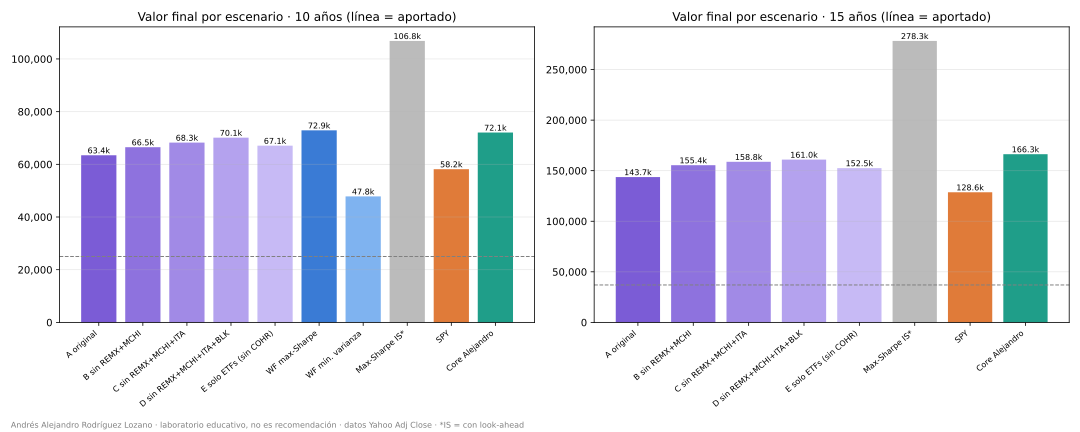

In [5]:
display(SVG(filename=str(OUT / 'valor_final_escenarios.svg')))

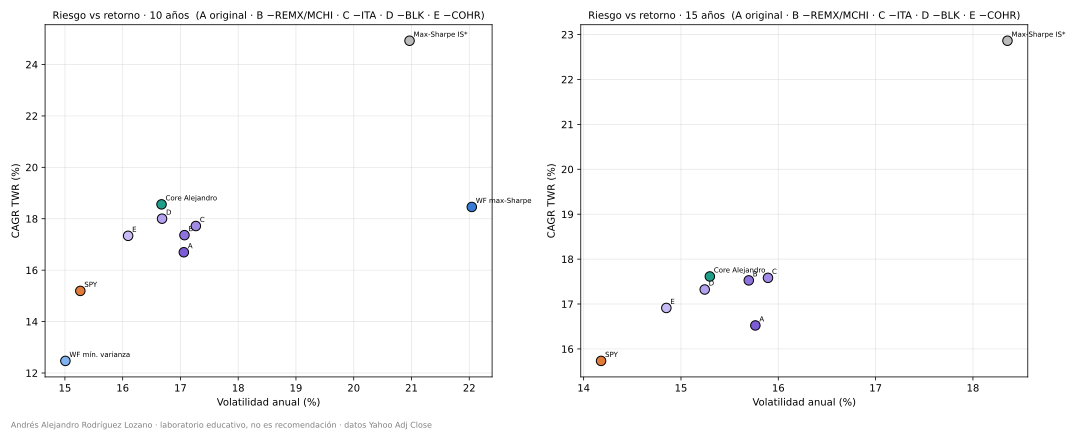

In [6]:
display(SVG(filename=str(OUT / 'riesgo_retorno.svg')))

**Lectura:** de A a D el valor final sube de forma monótona y la caída máxima (COVID) mejora de −35,9% a −32,3%. Pero mira la columna **2022**: C y D caen más que A (≈ −21/−22% vs −18%), porque ITA, BLK y SCHD eran justamente la parte defensiva.

## 4. ¿Se sostiene en dos subventanas?
Mismo flujo en oct-2016→sep-2021 y oct-2021→oct-2026 (cada una con su propio aporte inicial).

In [7]:
sens.set_index(['Ventana','Escenario'])[['Valor final','XIRR','Vol','Sharpe rf=4%','Max DD','Calmar']].style.format(
    {'Valor final':'US${:,.0f}','XIRR':'{:.1%}','Vol':'{:.1%}','Sharpe rf=4%':'{:.2f}','Max DD':'{:.1%}','Calmar':'{:.2f}'})

**Lectura:** D le gana a A en ambas mitades, pero B (quitar solo REMX+MCHI) **no** mejora en 2016–2021, y en 2021–2026 la caída máxima de C y D es peor que la de A. La mejora no es uniforme.

## 5. Redundancia
### 5.1 Correlación mensual

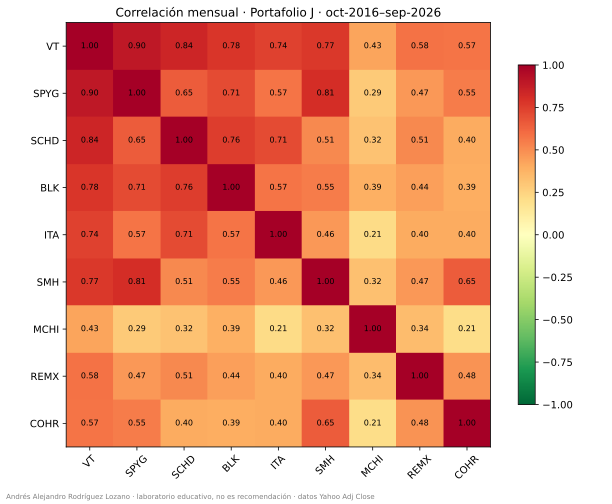

In [8]:
display(SVG(filename=str(OUT / 'correlacion.svg')))

VT correlaciona 0,90 con SPYG y 0,84 con SCHD: **VT ya contiene** buena parte de SPYG, SMH, BLK, COHR y China. Los menos correlacionados son **MCHI** y **REMX**, es decir, los diversificadores, no los redundantes.

### 5.2 R² y contribución al riesgo
- **R² vs los demás:** qué tanto del retorno de un activo explican los otros (cerca de 1 = redundante).
- **Contribución al riesgo** (Euler): `w_i·(Σw)_i / σ²_p`. Si *Riesgo/Peso* > 1, el activo pesa más en el riesgo que en el capital.

In [9]:
for k, v in red.items():
    print(k); display(v.style.format('{:.2f}'))
pd.DataFrame(red_sum).style.format('{:.2f}')

A original


,Peso,Vol anual,Contribución al riesgo,Riesgo/Peso,R² vs los demás,Corr con VT
VT,0.21,0.15,0.18,0.84,0.95,1.00
SPYG,0.21,0.17,0.19,0.92,0.89,0.90
SCHD,0.15,0.15,0.11,0.75,0.81,0.84
BLK,0.13,0.26,0.16,1.25,0.67,0.78
ITA,0.12,0.22,0.12,0.96,0.63,0.74
SMH,0.10,0.29,0.13,1.38,0.74,0.77
MCHI,0.03,0.24,0.02,0.60,0.35,0.43
REMX,0.03,0.39,0.05,1.42,0.41,0.58
COHR,0.03,0.50,0.05,1.85,0.47,0.57


D sin REMX+MCHI+ITA+BLK


,Peso,Vol anual,Contribución al riesgo,Riesgo/Peso,R² vs los demás,Corr con VT
VT,0.30,0.15,0.26,0.86,0.93,1.00
SPYG,0.30,0.17,0.30,0.98,0.86,0.90
SCHD,0.22,0.15,0.16,0.73,0.78,0.84
SMH,0.14,0.29,0.21,1.52,0.74,0.77
COHR,0.04,0.50,0.07,2.01,0.44,0.57


E solo ETFs (sin COHR)


,Peso,Vol anual,Contribución al riesgo,Riesgo/Peso,R² vs los demás,Corr con VT
VT,0.31,0.15,0.28,0.89,0.93,1.00
SPYG,0.31,0.17,0.32,1.02,0.85,0.90
SCHD,0.23,0.15,0.17,0.77,0.78,0.84
SMH,0.14,0.29,0.22,1.55,0.69,0.77


,A original,D sin REMX+MCHI+ITA+BLK,E solo ETFs (sin COHR)
Vol portafolio,0.17,0.17,0.16
Ratio diversificación (Σwσ/σp),1.23,1.13,1.10
N efectivo por pesos (1/Σw²),6.59,3.97,3.70
N efectivo por riesgo (1/Σrc²),7.09,4.34,3.81


Al cortar, el **ratio de diversificación** cae de 1,23 a 1,13 y el **número efectivo de apuestas por riesgo** de 7,1 a 4,3: el portafolio queda más concentrado en el mismo factor (EE. UU. crecimiento + semiconductores).

## 6. Optimización sin look-ahead (walk-forward)
Cada **octubre** (2016–2026) se estiman pesos con los **60 meses cerrados anteriores** y se aplican hacia adelante (fuera de muestra):
- **Max-Sharpe** (rf 4%) y **mínima varianza**.
- Long-only; cada activo entre **2% y 50%** si se incluye (si queda por debajo de 2% se saca y se re-optimiza).
- Universo: los 9 de Portafolio J.

La primera ventana (oct-2016) usa nov-2011–sep-2016 (59 meses) porque SCHD no tiene oct-2011 completo. **Ventana fuera de muestra: oct-2016–oct-2026.** No hay walk-forward de 15 años: haría falta historia de SCHD antes de 2011 y no inventamos series.

In [10]:
for k, l in wflog.items():
    print(k); display(l)

WF max-Sharpe (OOS)


,Fecha aplicación,Ventana desde,Ventana hasta,Meses
0,2016-10-03,2011-11,2016-09,59
1,2017-10-02,2012-10,2017-09,60
2,2018-10-01,2013-10,2018-09,60
3,2019-10-01,2014-10,2019-09,60
4,2020-10-01,2015-10,2020-09,60
5,2021-10-01,2016-10,2021-09,60
6,2022-10-03,2017-10,2022-09,60
7,2023-10-02,2018-10,2023-09,60
8,2024-10-01,2019-10,2024-09,60
9,2025-10-01,2020-10,2025-09,60


WF mín. varianza (OOS)


,Fecha aplicación,Ventana desde,Ventana hasta,Meses
0,2016-10-03,2011-11,2016-09,59
1,2017-10-02,2012-10,2017-09,60
2,2018-10-01,2013-10,2018-09,60
3,2019-10-01,2014-10,2019-09,60
4,2020-10-01,2015-10,2020-09,60
5,2021-10-01,2016-10,2021-09,60
6,2022-10-03,2017-10,2022-09,60
7,2023-10-02,2018-10,2023-09,60
8,2024-10-01,2019-10,2024-09,60
9,2025-10-01,2020-10,2025-09,60


In [11]:
for k, s in wf.items():
    print(k); display(s.style.format('{:.0%}'))

WF max-Sharpe (OOS)


,VT,SPYG,SCHD,BLK,ITA,SMH,MCHI,REMX,COHR
2016-10-03 00:00:00,0%,0%,39%,0%,50%,11%,0%,0%,0%
2017-10-02 00:00:00,0%,0%,0%,0%,50%,41%,0%,0%,9%
2018-10-01 00:00:00,0%,19%,0%,0%,50%,20%,0%,0%,11%
2019-10-01 00:00:00,0%,0%,0%,0%,50%,32%,0%,0%,18%
2020-10-01 00:00:00,0%,46%,0%,0%,0%,50%,0%,0%,4%
2021-10-01 00:00:00,0%,50%,0%,0%,0%,50%,0%,0%,0%
2022-10-03 00:00:00,0%,0%,50%,0%,0%,50%,0%,0%,0%
2023-10-02 00:00:00,0%,0%,50%,0%,0%,50%,0%,0%,0%
2024-10-01 00:00:00,0%,22%,22%,7%,0%,50%,0%,0%,0%
2025-10-01 00:00:00,0%,0%,0%,0%,50%,50%,0%,0%,0%


WF mín. varianza (OOS)


,VT,SPYG,SCHD,BLK,ITA,SMH,MCHI,REMX,COHR
2016-10-03 00:00:00,0%,25%,50%,0%,17%,0%,0%,0%,8%
2017-10-02 00:00:00,24%,9%,50%,0%,9%,0%,0%,0%,8%
2018-10-01 00:00:00,35%,0%,50%,0%,9%,0%,0%,0%,6%
2019-10-01 00:00:00,50%,0%,50%,0%,0%,0%,0%,0%,0%
2020-10-01 00:00:00,50%,0%,50%,0%,0%,0%,0%,0%,0%
2021-10-01 00:00:00,16%,27%,36%,0%,0%,0%,21%,0%,0%
2022-10-03 00:00:00,21%,0%,50%,0%,0%,0%,29%,0%,0%
2023-10-02 00:00:00,12%,19%,50%,0%,0%,0%,19%,0%,0%
2024-10-01 00:00:00,0%,28%,50%,0%,0%,0%,22%,0%,0%
2025-10-01 00:00:00,0%,27%,50%,0%,5%,0%,18%,0%,0%


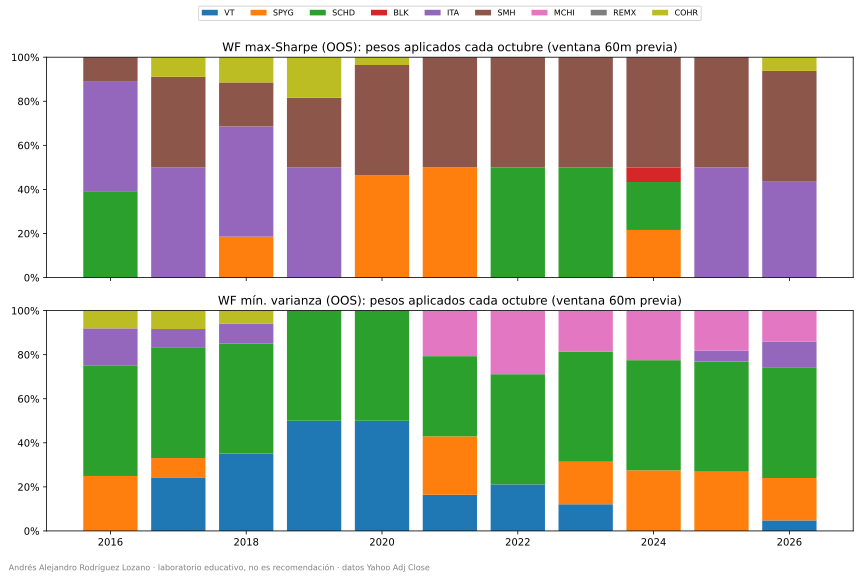

In [12]:
display(SVG(filename=str(OUT / 'pesos_walkforward.svg')))

**Lectura:** el max-Sharpe salta de activo en activo (ITA → SMH → SCHD → ITA) y casi siempre tiene algo pegado al 50%. Gana en valor final, pero con 22% de volatilidad y −41% de caída: **peor Sharpe que el original**. La mínima varianza se refugia en SCHD + VT y termina con el menor valor de todos.

## 7. El espejismo: max-Sharpe in-sample
Si optimizamos **conociendo** todo el periodo, el resultado es espectacular, y por eso es engañoso: usa información que nadie tenía en 2016. Lo dejamos solo como techo **optimista, con look-ahead**.

In [13]:
pd.DataFrame(ins).T.style.format('{:.1%}')

,VT,SPYG,SCHD,BLK,ITA,SMH,MCHI,REMX,COHR
10 años,0.0%,21.3%,26.3%,0.0%,0.0%,50.0%,0.0%,0.0%,2.4%
15 años,0.0%,12.2%,23.6%,0.0%,14.3%,50.0%,0.0%,0.0%,0.0%


## 8. Validaciones

In [14]:
for v in vals: print('✔', v)

✔ WF max-Sharpe (OOS): pesos suman 1, ≤50%, 0 o ≥2%; ventana termina antes de cada fecha; alterar retornos >2020-12 no cambia pesos 2016-2020
✔ WF mín. varianza (OOS): pesos suman 1, ≤50%, 0 o ≥2%; ventana termina antes de cada fecha; alterar retornos >2020-12 no cambia pesos 2016-2020
✔ 10 años · Core: sin NaN, 120 aportes + inicial = US$25,000, sin look-ahead, contabilidad OK
✔ 10 años · A original: sin NaN, 120 aportes + inicial = US$25,000, sin look-ahead, contabilidad OK
✔ 10 años · B sin REMX+MCHI: sin NaN, 120 aportes + inicial = US$25,000, sin look-ahead, contabilidad OK
✔ 10 años · C sin REMX+MCHI+ITA: sin NaN, 120 aportes + inicial = US$25,000, sin look-ahead, contabilidad OK
✔ 10 años · D sin REMX+MCHI+ITA+BLK: sin NaN, 120 aportes + inicial = US$25,000, sin look-ahead, contabilidad OK
✔ 10 años · E solo ETFs (sin COHR): sin NaN, 120 aportes + inicial = US$25,000, sin look-ahead, contabilidad OK
✔ 10 años · WF max-Sharpe (OOS): sin NaN, 120 aportes + inicial = US$25,000, sin

## 9. Conclusión honesta
1. **La hipótesis es débil en su forma fuerte.** D mejora valor final y caída máxima, pero **pierde defensa en 2022** y **diversificación** (7,1 → 4,3 apuestas efectivas), y en 2021–2026 su caída máxima es algo peor.
2. **Los cortes se eligieron ex post.** Quitamos lo que hoy sabemos que rindió poco (MCHI, REMX); por eso E (sin COHR, un ganador ex post) rinde menos que D. Eso es sesgo de retrospectiva.
3. **Los "redundantes" no eran los cortados:** el más redundante es VT (R² 0,95); MCHI y REMX eran los más descorrelacionados.
4. **El walk-forward no agrega valor ajustado por riesgo:** el max-Sharpe es inestable y más riesgoso; la mínima varianza se queda atrás.
5. Simplificar acerca el portafolio a un core tipo SPYG + SMH + diversificador, pero ninguna variante supera al core de referencia de forma consistente.

*Andrés Alejandro Rodríguez Lozano · laboratorio, no recomendación · octubre 2026*